In [24]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.datasets import load_wine

from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score

In [25]:
wine = load_wine()

X = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

y = wine.target


print("Dataset Shape:")
print(X.shape)

print("\nFeatures:")
print(X.columns)

Dataset Shape:
(178, 13)

Features:
Index(['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium',
       'total_phenols', 'flavanoids', 'nonflavanoid_phenols',
       'proanthocyanins', 'color_intensity', 'hue',
       'od280/od315_of_diluted_wines', 'proline'],
      dtype='object')


In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [27]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)


rf_model.fit(
    X_train,
    y_train
)


y_pred = rf_model.predict(X_test)


baseline_accuracy = accuracy_score(
    y_test,
    y_pred
)


print(
    "Baseline Accuracy:",
    baseline_accuracy
)

Baseline Accuracy: 1.0


In [28]:
importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance": rf_model.feature_importances_

})


importance = importance.sort_values(
    by="Importance",
    ascending=False
)


print(importance)

                         Feature  Importance
6                     flavanoids    0.202293
9                color_intensity    0.171202
12                       proline    0.139046
0                        alcohol    0.112398
11  od280/od315_of_diluted_wines    0.111564
10                           hue    0.070891
4                      magnesium    0.036841
1                     malic_acid    0.035703
3              alcalinity_of_ash    0.032425
5                  total_phenols    0.029279
8                proanthocyanins    0.023561
2                            ash    0.021282
7           nonflavanoid_phenols    0.013515


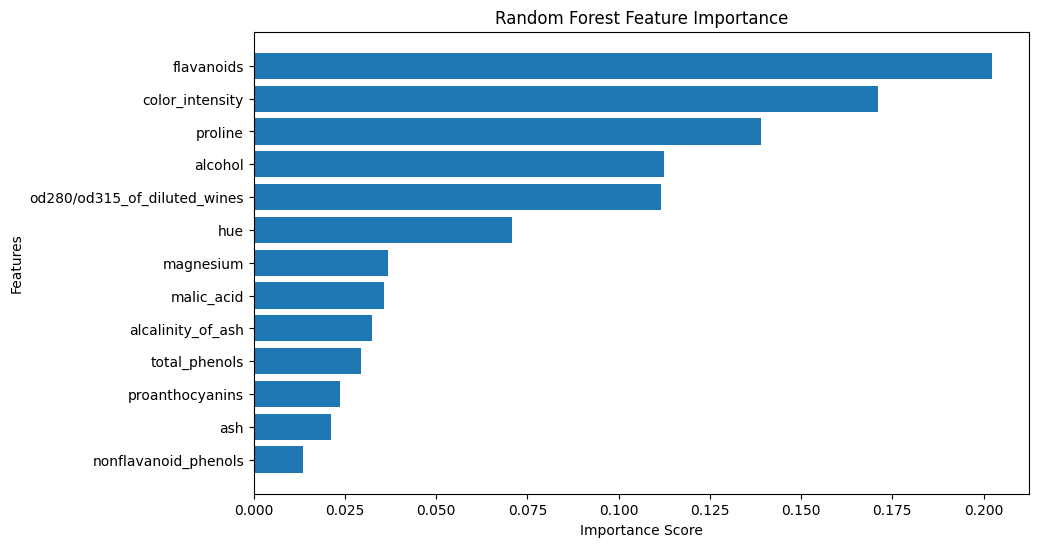

In [29]:
plt.figure(figsize=(10,6))


plt.barh(
    importance["Feature"],
    importance["Importance"]
)


plt.xlabel("Importance Score")

plt.ylabel("Features")

plt.title(
    "Random Forest Feature Importance"
)


plt.gca().invert_yaxis()


plt.show()

In [30]:
top_features = importance.head(5)


print("Top 5 Features")

print(top_features)

Top 5 Features
                         Feature  Importance
6                     flavanoids    0.202293
9                color_intensity    0.171202
12                       proline    0.139046
0                        alcohol    0.112398
11  od280/od315_of_diluted_wines    0.111564


In [31]:
selected_features = top_features["Feature"].values


X_train_top = X_train[selected_features]

X_test_top = X_test[selected_features]

In [32]:
rf_top_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)


rf_top_model.fit(
    X_train_top,
    y_train
)


top_pred = rf_top_model.predict(
    X_test_top
)


top_accuracy = accuracy_score(
    y_test,
    top_pred
)


print(
    "Top 5 Feature Accuracy:",
    top_accuracy
)

Top 5 Feature Accuracy: 0.9722222222222222


In [33]:
comparison = pd.DataFrame({

    "Model":[
        "All Features",
        "Top 5 Features"
    ],

    "Accuracy":[
        baseline_accuracy,
        top_accuracy
    ]

})


print(comparison)

            Model  Accuracy
0    All Features  1.000000
1  Top 5 Features  0.972222


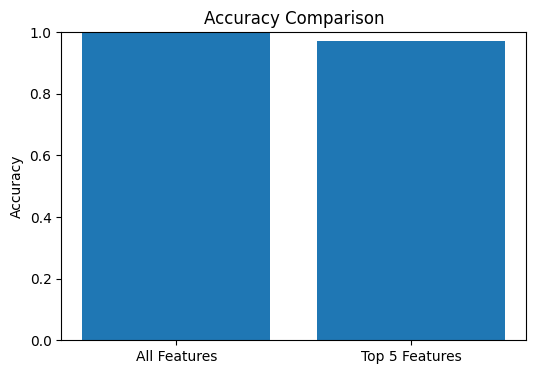

In [34]:
plt.figure(figsize=(6,4))


plt.bar(
    comparison["Model"],
    comparison["Accuracy"]
)


plt.ylabel("Accuracy")

plt.title(
    "Accuracy Comparison"
)


plt.ylim(0,1)


plt.show()